In [81]:
import matplotlib.pyplot as plt 
import tensorflow as tf 
import numpy as np 
import pandas as pd 
import keras 
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from keras.layers import Dense 
from keras.models import Sequential  


In [82]:
X, y = make_moons(n_samples = 300 , noise= 0.05 ,random_state = 42 )


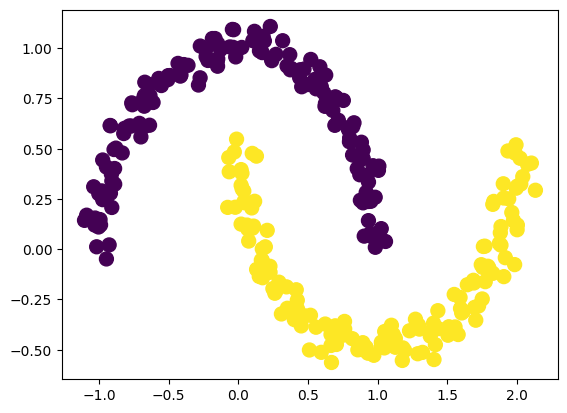

In [83]:
plt.scatter(X[ : ,0 ], X[ : ,1 ], c = y , s= 100 )
plt.show()

In [ ]:
model = Sequential()
model.add(Dense(10 , activation= 'relu', input_dim = 2 ))
# model.add(Dense(10 , activation= 'sigmoid' ))
# model.add(Dense(10 , activation= 'sigmoid' ))
# model.add(Dense(10 , activation= 'sigmoid' ))
# model.add(Dense(10 , activation= 'sigmoid' ))
# model.add(Dense(10 , activation= 'sigmoid' ))
# model.add(Dense(10 , activation= 'sigmoid' ))
# model.add(Dense(10 , activation= 'sigmoid' ))
# model.add(Dense(10 , activation= 'sigmoid' ))
# model.add(Dense(10 , activation= 'sigmoid' ))
model.add(Dense(10 , activation= 'relu' ))
model.add(Dense(10 , activation= 'relu' ))
model.add(Dense(10 , activation= 'relu' ))
model.add(Dense(10 , activation= 'relu' ))
model.add(Dense(10 , activation= 'relu' ))
model.add(Dense(10 , activation= 'relu' ))
model.add(Dense(10 , activation= 'relu' ))
model.add(Dense(10 , activation= 'relu' ))
model.add(Dense(10 , activation= 'relu' ))
model.add(Dense(10 , activation= 'relu' ))
model.add(Dense(10 , activation= 'sigmoid' ))
model.add(Dense(1  , activation= 'sigmoid' )) # last layer activation function cannot be changed 



In [85]:
model.compile(loss = 'binary_crossentropy', optimizer = 'adam', metrics = ['accuracy'])

In [86]:
old_weights = model.get_weights()[0] 

In [87]:
model.get_weights()[0] 

array([[-0.46255222,  0.33163935, -0.46586275,  0.2388143 , -0.5114807 ,
         0.48072892,  0.6925271 ,  0.20818484, -0.67871094,  0.00601047],
       [-0.21701363, -0.0421797 , -0.04470229,  0.6580185 , -0.35115355,
         0.3352396 ,  0.4954229 , -0.46398857, -0.5585331 ,  0.1530748 ]],
      dtype=float32)

In [88]:
X_train , X_test , y_train , y_test = train_test_split(X, y , test_size = 0.2 , random_state = 42 )

In [ ]:
epochs = 100
model.fit(X_train , y_train, epochs = epochs ) 

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 1.0000 - loss: 2.0019e-04 


In [97]:
new_weights = model.get_weights()[0]

In [98]:
lr = learning_rate = model.optimizer.get_config()["learning_rate"]

In [99]:
print(f"""this  shows the gradient of 1st layer in {epochs} epoch, & it is very less , this is why VANISHING GRADIENT PROBLEM HAPPENS""")
# This weights are multiplied later & form even smaller weights that leads to almost no change in new_weights 
gradient = derivative = (old_weights - new_weights)/lr
gradient

this  shows the gradient of 1st layer in 1 epoch, & it is very less , this is why VANISHING GRADIENT PROBLEM HAPPENS


array([[ 152.38437  , -142.57306  ,   -4.6775637,  -36.87447  ,
         143.79059  , -124.51767  , -208.32544  ,  -86.26177  ,
         156.67676  ,   60.026268 ],
       [-112.65813  ,   90.090645 ,   61.720493 ,  -36.51619  ,
         -91.27995  ,  118.54846  ,  132.18828  ,  170.34134  ,
        -109.15267  ,  -95.51396  ]], dtype=float32)

In [100]:
# This shows how much percentage the weights are changed in one epoch 
percentage_change = abs(100*(old_weights - new_weights)/old_weights)
percentage_change

array([[ 32.944252 ,  42.990395 ,   1.0040648,  15.440647 ,  28.112617 ,
         25.90185  ,  30.081919 ,  41.43519  ,  23.084461 , 998.69464  ],
       [ 51.912933 , 213.58768  , 138.0701   ,   5.5494165,  25.994314 ,
         35.362312 ,  26.68191  ,  36.7124   ,  19.542742 ,  62.396927 ]],
      dtype=float32)

In [101]:
""" You can also compare old_weights & new_weights together """
old_weights 


array([[-0.46255222,  0.33163935, -0.46586275,  0.2388143 , -0.5114807 ,
         0.48072892,  0.6925271 ,  0.20818484, -0.67871094,  0.00601047],
       [-0.21701363, -0.0421797 , -0.04470229,  0.6580185 , -0.35115355,
         0.3352396 ,  0.4954229 , -0.46398857, -0.5585331 ,  0.1530748 ]],
      dtype=float32)

In [102]:
"""Both old & new weights are almost same & no change happend in these when VANISHING GRADIENT PROBLEM HAPPEND """
new_weights

array([[-0.6149366 ,  0.4742124 , -0.4611852 ,  0.27568877, -0.6552713 ,
         0.6052466 ,  0.90085256,  0.29444662, -0.8353877 , -0.0540158 ],
       [-0.10435549, -0.13227035, -0.10642279,  0.6945347 , -0.2598736 ,
         0.21669112,  0.3632346 , -0.6343299 , -0.4493804 ,  0.24858877]],
      dtype=float32)